<a href="https://colab.research.google.com/github/nukitos25-prog/IT_for_me/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 13. Основы обучаемых алгоритмов

ФИО: Стрельцов Никита Андреевич

Группа: ИНБ-б-о-26-1(1)

## Задание

Напишите скрипт для решения задачи в блокноте Python Notebook или с
использованием локального интерпретатора в соответствии с индивидуальным
вариантом.
Файлы для выполнения индивидуального задания:

https://github.com/enikolaev/IT-and-Programming/tree/main/data/pract13

В каждом варианте необходимо выполнить визуализацию данных,
хранящихся в файле с использованием библиотеки matplotlib. Необходимо обучить
модель регрессии и найти значения параметров, а также визуализировать факт, что
ваша модель хорошо интерпретирует эмпирические данные. Необходимо провести
эксперименты со следующими параметрами: скорость обучения, начальные
значения параметров. Определите их влияние на процесс обучения алгоритма.

## Решение

Загружено 500 точек
Диапазон X: [-2.58, 3.07]
Диапазон y: [-187.03, 188.51]


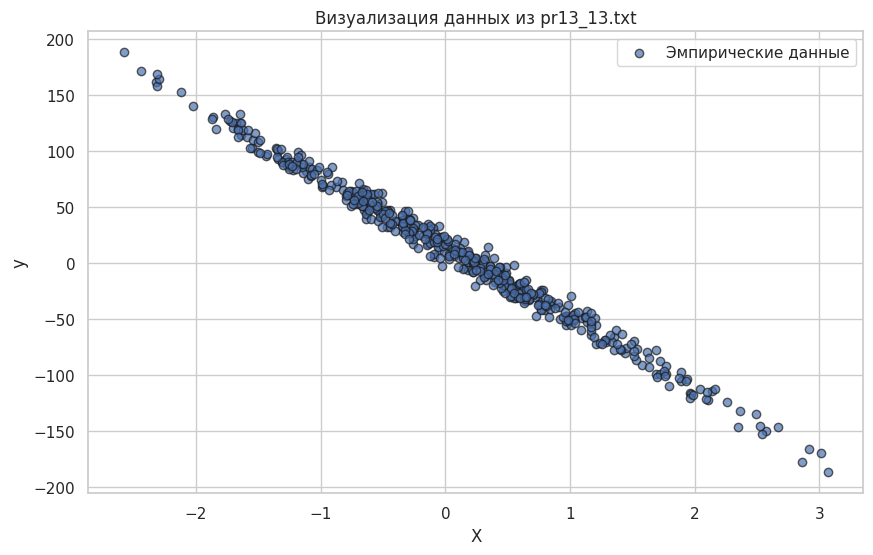

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стиля графиков
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Загрузка данных для варианта 13
!wget -q https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract13/pr13_13.txt

# Чтение данных
X, y = [], []
with open('pr13_13.txt', 'r') as f:
    for line in f:
        s = line.strip().split()
        if len(s) >= 2:
            X.append([float(s[0])])
            y.append([float(s[1])])

X = np.array(X)
y = np.array(y)

print(f"Загружено {X.shape[0]} точек")
print(f"Диапазон X: [{X.min():.2f}, {X.max():.2f}]")
print(f"Диапазон y: [{y.min():.2f}, {y.max():.2f}]")

# Визуализация исходных данных
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.7, edgecolor='k', label='Эмпирические данные')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Визуализация данных из pr13_13.txt')
plt.legend()
plt.show()

In [2]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iters=1000, random_state=None):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Инициализация параметров
        if self.random_state is not None:
            np.random.seed(self.random_state)
            self.weights = np.random.randn(n_features, 1) * 0.01
            self.bias = np.random.randn(1) * 0.01
        else:
            self.weights = np.zeros((n_features, 1))
            self.bias = 0.0

        y = y.reshape(-1, 1)
        self.loss_history = []

        for i in range(self.n_iters):
            # Предсказание
            y_pred = X @ self.weights + self.bias
            # Вычисление ошибки (MSE)
            error = y_pred - y
            loss = np.mean(error ** 2)
            self.loss_history.append(loss)

            # Градиенты
            dw = (2 / n_samples) * (X.T @ error)
            db = (2 / n_samples) * np.sum(error)

            # Обновление параметров
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

        return self

    def predict(self, X):
        return X @ self.weights + self.bias

Найденные параметры модели:
  Вес (w): -62.9053
  Смещение (b): 14.2303


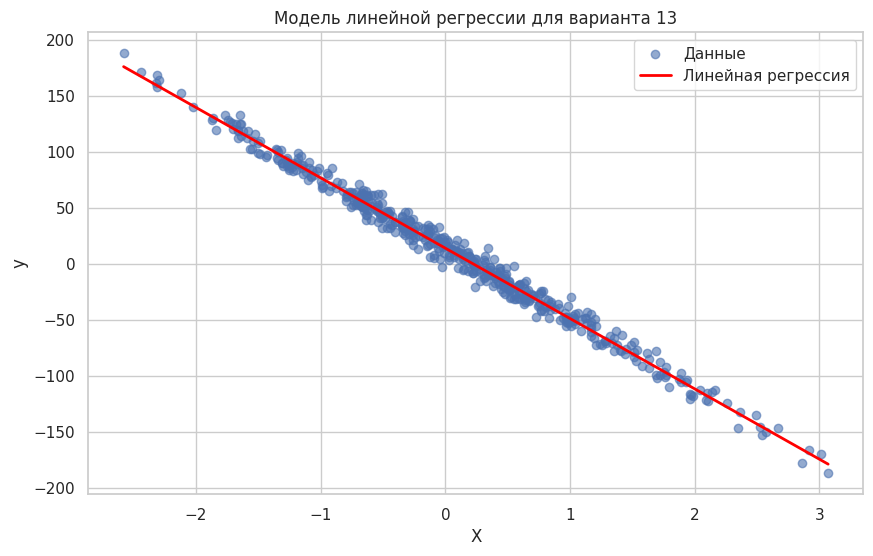

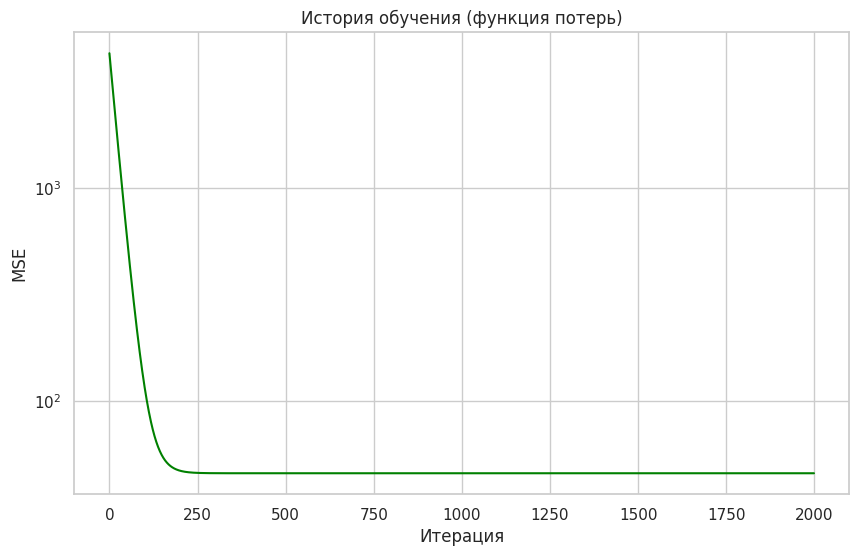

In [3]:
# Создание и обучение модели
model = LinearRegressionGD(learning_rate=0.01, n_iters=2000)
model.fit(X, y)

# Вывод найденных параметров
print("Найденные параметры модели:")
print(f"  Вес (w): {model.weights[0, 0]:.4f}")
print(f"  Смещение (b): {model.bias:.4f}")

# Визуализация
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.6, label='Данные')

# Линия регрессии
x_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_pred_line = model.predict(x_range)

plt.plot(x_range, y_pred_line, color='red', linewidth=2, label='Линейная регрессия')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Модель линейной регрессии для варианта 13')
plt.legend()
plt.show()

# График функции потерь
plt.figure(figsize=(10, 6))
plt.plot(model.loss_history, color='green')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('История обучения (функция потерь)')
plt.yscale('log')
plt.show()

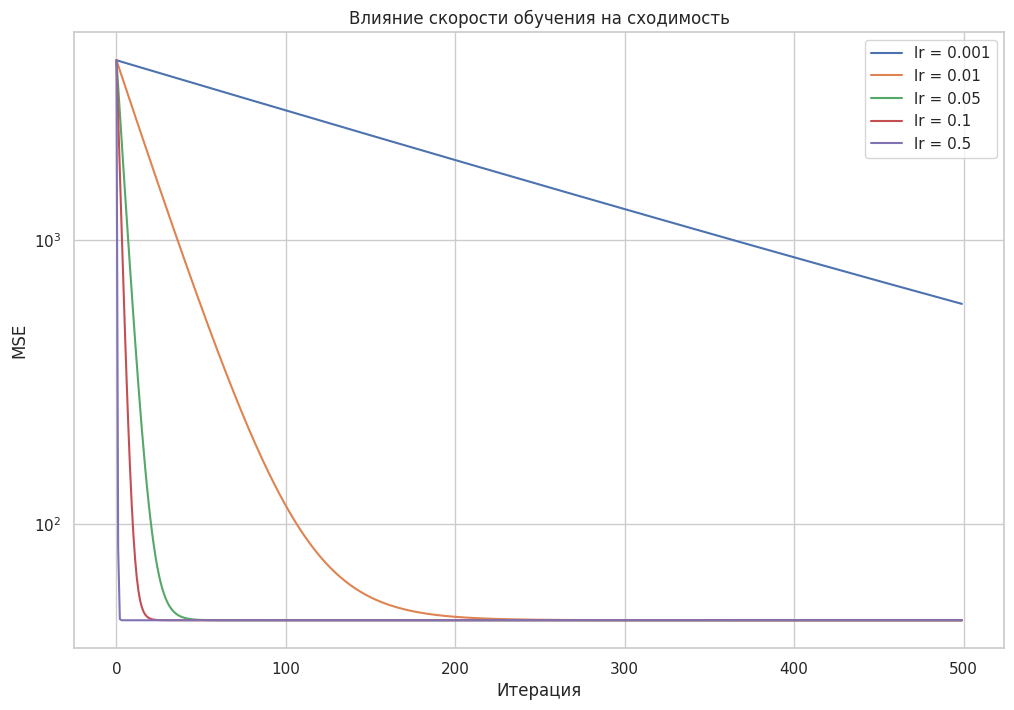

In [4]:
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.5]
plt.figure(figsize=(12, 8))

for lr in learning_rates:
    m = LinearRegressionGD(learning_rate=lr, n_iters=500)
    m.fit(X, y)
    plt.plot(m.loss_history, label=f'lr = {lr}')

plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Влияние скорости обучения на сходимость')
plt.legend()
plt.yscale('log')
plt.show()

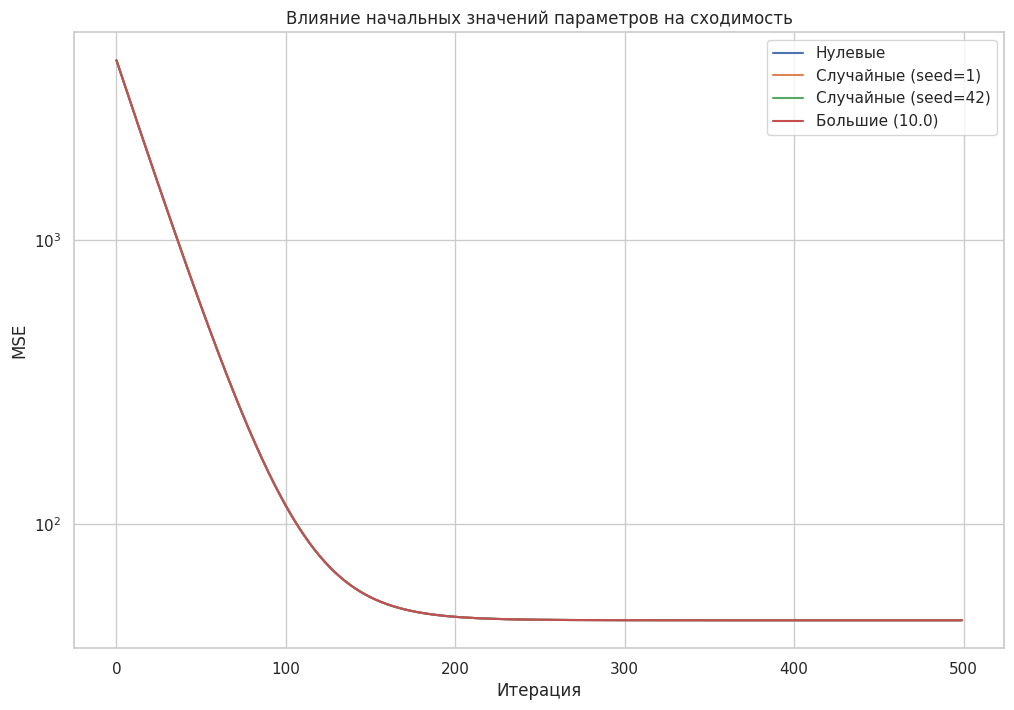

In [5]:
initializations = {
    'Нулевые': None,
    'Случайные (seed=1)': 1,
    'Случайные (seed=42)': 42,
    'Большие (10.0)': 'large'
}

plt.figure(figsize=(12, 8))

for name, seed in initializations.items():
    if seed == 'large':
        # Специальная инициализация большими значениями
        m = LinearRegressionGD(learning_rate=0.01, n_iters=500)
        m.weights = np.array([[10.0]])
        m.bias = 10.0
        m.fit(X, y)
    else:
        m = LinearRegressionGD(learning_rate=0.01, n_iters=500, random_state=seed)
        m.fit(X, y)
    plt.plot(m.loss_history, label=name)

plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Влияние начальных значений параметров на сходимость')
plt.legend()
plt.yscale('log')
plt.show()

## Контрольные вопросы

1. Действительно ли алгоритмы могут обучаться? В чем заключается процесс
обучения?

Да, алгоритмы машинного обучения действительно «обучаются» — но не в биологическом смысле, а в математическом: они настраивают свои параметры так, чтобы минимизировать ошибку на данных.

Процесс обучения заключается в следующем:

Задаётся модель с настраиваемыми параметрами (например, y=wx+b).

Определяется функция потерь (loss function), которая измеряет, насколько предсказания модели отличаются от истинных значений (например, MSE — среднеквадратичная ошибка).

Выбирается алгоритм оптимизации (например, градиентный спуск), который итеративно изменяет параметры в направлении уменьшения функции потерь.

Процесс повторяется, пока ошибка не перестанет уменьшаться или не будет достигнуто заданное число итераций.

2. Что такое модель линейной регрессии?

Модель линейной регрессии — это простейшая модель машинного обучения, которая предполагает линейную зависимость между входными признаками X и целевой переменной y.

3. Каким образом производится подбор параметров модели в процессе
градиентного спуска?

Градиентный спуск — это итеративный метод оптимизации, который находит минимум функции потерь, двигаясь в направлении, противоположном градиенту.

Алгоритм:

1) Инициализировать параметры w и b (нулями, случайными числами и т.д.).

2) Вычислить предсказания модели: y^=wx+b.

3) Вычислить функцию потерь, например MSE:

$$
L = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2
$$

4) Вычислить градиенты функции потерь по параметрам:

$$
\frac{\partial L}{\partial w} = \frac{2}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i) \cdot x_i,
\qquad
\frac{\partial L}{\partial b} = \frac{2}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)
$$

5) Обновить параметры в направлении, противоположном градиенту:

$$
w := w - \alpha \frac{\partial L}{\partial w},
\qquad
b := b - \alpha \frac{\partial L}{\partial b}
$$ где α — скорость обучения (learning rate).

6) Повторять шаги 2–5 до сходимости (пока ошибка не стабилизируется или не будет достигнуто максимальное число итераций).

4. Что такое темп обучения? Как влияет данный гиперпараметр на процесс
обучения?

Темп обучения (скорость обучения, learning rate, α) — это гиперпараметр, который определяет размер шага при обновлении параметров в градиентном спуске.

Влияние на обучение:

Слишком маленький темп (α≪1): алгоритм сходится очень медленно, требуется много итераций; обучение может затянуться.

Умеренный темп (подбирается экспериментально): быстрая и стабильная сходимость к минимуму.

Слишком большой темп (α велик): алгоритм может «перепрыгивать» минимум, колебаться вокруг него или даже расходиться (ошибка растёт с каждой итерацией).

5. Перечислите основные типы диаграмм matplotlib и функции, которые
реализуют построение графиков данных типов.

Matplotlib предоставляет широкий набор типов диаграмм. Основные из них:

Тип диаграммы ---	Функция matplotlib ---	Назначение

Линейный график ---	plt.plot(x, y)	--- Зависимость одной величины от другой (тренды, функции)

Точечная диаграмма --- (scatter)	plt.scatter(x, y) ---	Отображение отдельных точек, поиск корреляций

Гистограмма ---	plt.hist(data, bins=...) ---	Распределение значений (частота попадания в интервалы)

Столбчатая диаграмма ---	plt.bar(x, height) ---	Сравнение категорий (значения по категориям)

Горизонтальная столбчатая ---	plt.barh(y, width) ---	То же, но с горизонтальными столбцами

Круговая диаграмма ---	plt.pie(sizes, labels=...) ---	Доли целого (проценты)

Ящик с усами --- (boxplot)	plt.boxplot(data) ---	Разброс, медиана, выбросы

Тепловая карта ---	plt.imshow(matrix) / sns.heatmap ---	Матрицы значений (корреляции, изображения)

Степенная диаграмма --- (stem)	plt.stem(x, y) ---	Дискретные последовательности

Диаграмма ошибок ---	plt.errorbar(x, y, yerr=...) ---	Значения с погрешностями

Заполненная область ---	plt.fill_between(x, y1, y2) ---	Область между кривыми

Контурный график ---	plt.contour / plt.contourf ---	Двумерные распределения (линии уровня)